<a href="https://colab.research.google.com/github/Dedeepya0510/CSA4703---Deep-Learning/blob/main/Lab%20Experiment/Exp_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

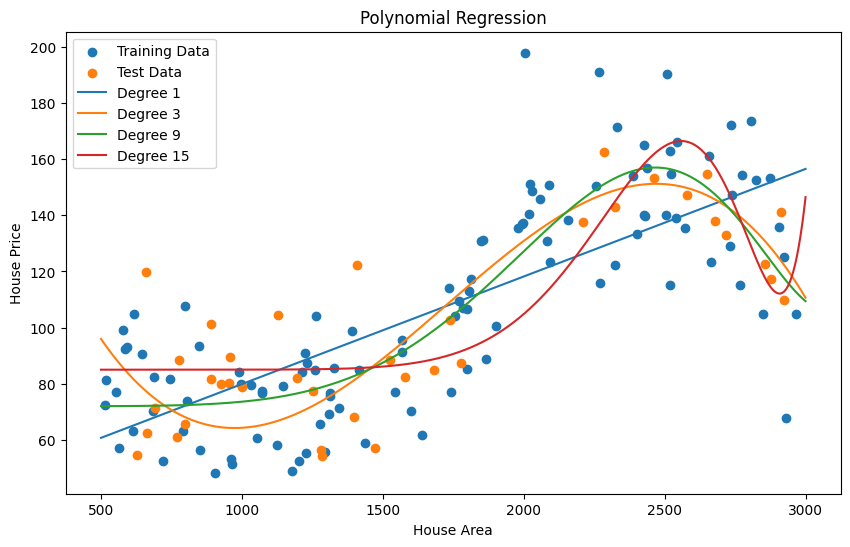

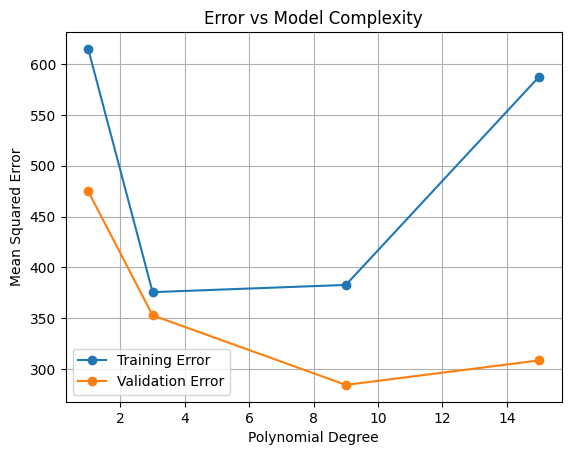

Bias Squared: 55.18798722226085
Variance: 15.87438775166703
Best Polynomial Degree: 9
Validation Error: 284.50292172428766


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

np.random.seed(42)

# Generate House Price Dataset
X = np.sort(np.random.uniform(500,3000,150)).reshape(-1,1)

y = (
    50 + 0.035*X.ravel()
    - 0.000012*(X.ravel()-1700)**2
    + 25*np.sin(X.ravel()/300)
    + np.random.normal(0,18,150)
)

X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.25,random_state=42
)

degrees = [1,3,9,15]

train_errors = []
test_errors = []

grid = np.linspace(500,3000,400).reshape(-1,1)

# 1 and 2. Polynomial Regression
plt.figure(figsize=(10,6))
plt.scatter(X_train,y_train,label="Training Data")
plt.scatter(X_test,y_test,label="Test Data")

for d in degrees:

    poly = PolynomialFeatures(degree=d)

    X_poly = poly.fit_transform(X_train)

    model = LinearRegression()
    model.fit(X_poly,y_train)

    prediction = model.predict(poly.transform(grid))

    plt.plot(grid,prediction,label=f"Degree {d}")

    train_errors.append(
        mean_squared_error(y_train,model.predict(X_poly))
    )

    test_errors.append(
        mean_squared_error(
            y_test,model.predict(poly.transform(X_test))
        )
    )

plt.xlabel("House Area")
plt.ylabel("House Price")
plt.title("Polynomial Regression")
plt.legend()
plt.show()

# 3. Training and Validation Errors
plt.plot(degrees,train_errors,'o-',label="Training Error")
plt.plot(degrees,test_errors,'o-',label="Validation Error")

plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error")
plt.title("Error vs Model Complexity")
plt.legend()
plt.grid()
plt.show()

# 4. Bias and Variance using Bootstrap
predictions = []

for seed in range(40):

    rng = np.random.default_rng(seed)

    idx = rng.integers(0,len(X_train),len(X_train))

    poly = PolynomialFeatures(degree=3)

    model = LinearRegression()

    model.fit(
        poly.fit_transform(X_train[idx]),
        y_train[idx]
    )

    predictions.append(
        model.predict(poly.transform(grid))
    )

predictions = np.array(predictions)

true_curve = (
    50 + 0.035*grid.ravel()
    - 0.000012*(grid.ravel()-1700)**2
    + 25*np.sin(grid.ravel()/300)
)

bias_squared = np.mean(
    (predictions.mean(axis=0)-true_curve)**2
)

variance = np.mean(np.var(predictions,axis=0))

print("Bias Squared:",bias_squared)
print("Variance:",variance)

# 5. Best Model
best_degree = degrees[np.argmin(test_errors)]

print("Best Polynomial Degree:",best_degree)
print("Validation Error:",min(test_errors))